# # Реализация алгоритма Martins SQA

## Цель
Разработать алгоритм оценки качества одноканальной ЭКГ
на основе морфологического сходства QRS/PQRST-комплексов
и физиологической правдоподобности RR-интервалов.

## Этап 1. Подготовка комплексов и шаблонов

На первом этапе:
- выделяем 15-секундный сегмент;
- выбираем соответствующие ему аннотации;
- извлекаем QRS- и PQRST-комплексы;
- строим усреднённые шаблоны.

В качестве положений сердечных сокращений
используются экспертные аннотации MIT-BIH.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

# Находим корень репозитория
current_dir = Path.cwd()

repo_root = next(
    (
        p for p in (current_dir, *current_dir.parents)
        if (p / ".git").exists()
    ),
    None
)

if repo_root is None:
    raise FileNotFoundError("Не найден Git-репозиторий")

# Путь к подготовленной записи
DATA_PATH = (
    repo_root
    / "data"
    / "processed"
    / "mitdb_100_250hz.npz"
)

# Загружаем данные
with np.load(DATA_PATH, allow_pickle=False) as data:
    ecg = data["ecg"].astype(np.float64)
    fs = int(data["fs"].item())
    reference_beats = data["beat_samples"].astype(int)
    reference_symbols = data["beat_symbols"]

print(f"Частота дискретизации: {fs} Гц")
print(f"Длительность записи: {len(ecg) / fs:.2f} с")
print(f"Количество сокращений: {len(reference_beats)}")

Частота дискретизации: 250 Гц
Длительность записи: 1805.56 с
Количество сокращений: 2273


In [2]:
SEGMENT_DURATION_SEC = 15
MARGIN_SEC = 1

START_SEC = 30
END_SEC = START_SEC + SEGMENT_DURATION_SEC

# Границы основного сегмента
start_sample = int(round(START_SEC * fs))
end_sample = int(round(END_SEC * fs))

# Границы с дополнительной секундой
context_start = int(round((START_SEC - MARGIN_SEC) * fs))
context_end = int(round((END_SEC + MARGIN_SEC) * fs))

# Проверяем, что границы находятся внутри записи
assert context_start >= 0
assert context_end <= len(ecg)

# Основной сегмент
ecg_segment = ecg[start_sample:end_sample]

# Сегмент с дополнительными данными
ecg_context = ecg[context_start:context_end]

# Выбираем сокращения только в основных 15 секундах
beat_mask = (
    (reference_beats >= start_sample)
    & (reference_beats < end_sample)
)

segment_beats = reference_beats[beat_mask]

# Переводим координаты сокращений в систему ecg_context
local_beats = segment_beats - context_start

print("Основной сегмент:", len(ecg_segment), "отсчётов")
print("С контекстом:", len(ecg_context), "отсчётов")
print("Сокращений внутри сегмента:", len(segment_beats))

Основной сегмент: 3750 отсчётов
С контекстом: 4250 отсчётов
Сокращений внутри сегмента: 19


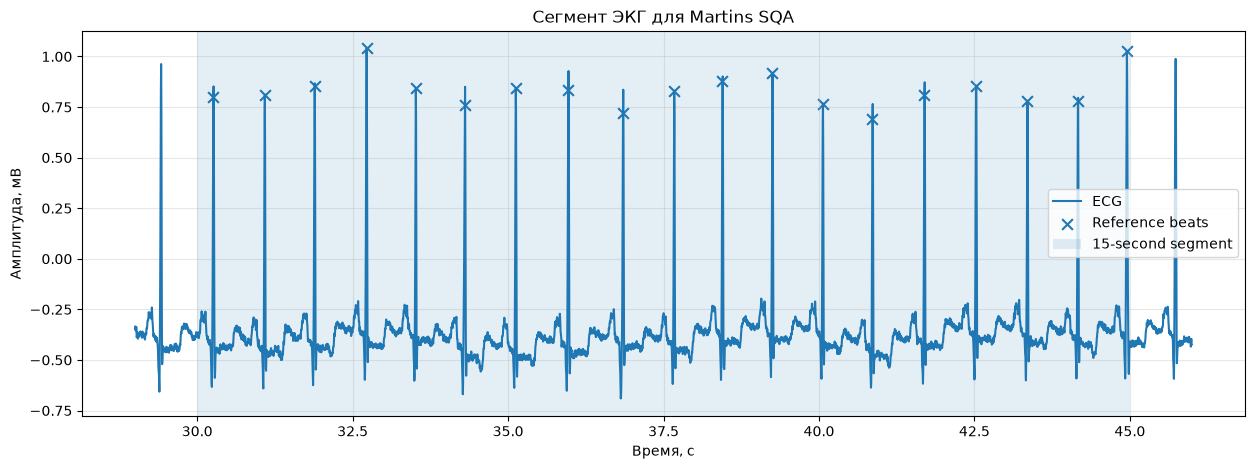

In [3]:
time = np.arange(
    context_start,
    context_end
) / fs

plt.figure(figsize=(15, 5))

plt.plot(
    time,
    ecg_context,
    label="ECG"
)

plt.scatter(
    segment_beats / fs,
    ecg[segment_beats],
    marker="x",
    s=60,
    label="Reference beats"
)

plt.axvspan(
    START_SEC,
    END_SEC,
    alpha=0.12,
    label="15-second segment"
)

plt.xlabel("Время, с")
plt.ylabel("Амплитуда, мВ")
plt.title("Сегмент ЭКГ для Martins SQA")

plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [4]:
def extract_complexes(
    signal,
    centers,
    fs,
    before_ms,
    after_ms
):
    # Переводим миллисекунды в число отсчётов
    n_before = int(round(before_ms / 1000 * fs))
    n_after = int(round(after_ms / 1000 * fs))

    # Список извлечённых комплексов
    complexes = []

    for center in centers:

        # Начало и конец комплекса
        left = int(center) - n_before
        right = int(center) + n_after + 1

        # Проверяем границы
        if left < 0 or right > len(signal):
            raise ValueError(
                "Комплекс выходит за границы сигнала"
            )

        # Сохраняем фрагмент
        complexes.append(signal[left:right])

    if not complexes:
        raise ValueError("В сегменте нет сокращений")

    # Преобразуем список в двумерный массив
    complexes = np.stack(complexes, axis=0)

    # Временная ось относительно центра
    relative_time_ms = (
        np.arange(-n_before, n_after + 1)
        / fs * 1000
    )

    return complexes, relative_time_ms

In [5]:
# QRS: -50 ... +50 мс
qrs_complexes, qrs_time = extract_complexes(
    signal=ecg_context,
    centers=local_beats,
    fs=fs,
    before_ms=50,
    after_ms=50
)

# PQRST: -300 ... +500 мс
pqrst_complexes, pqrst_time = extract_complexes(
    signal=ecg_context,
    centers=local_beats,
    fs=fs,
    before_ms=300,
    after_ms=500
)

print("QRS shape:", qrs_complexes.shape)
print("PQRST shape:", pqrst_complexes.shape)

QRS shape: (19, 25)
PQRST shape: (19, 201)


In [6]:
qrs_template = np.mean(
    qrs_complexes,
    axis=0
)

pqrst_template = np.mean(
    pqrst_complexes,
    axis=0
)

print("Размер QRS-шаблона:", qrs_template.shape)
print("Размер PQRST-шаблона:", pqrst_template.shape)

Размер QRS-шаблона: (25,)
Размер PQRST-шаблона: (201,)


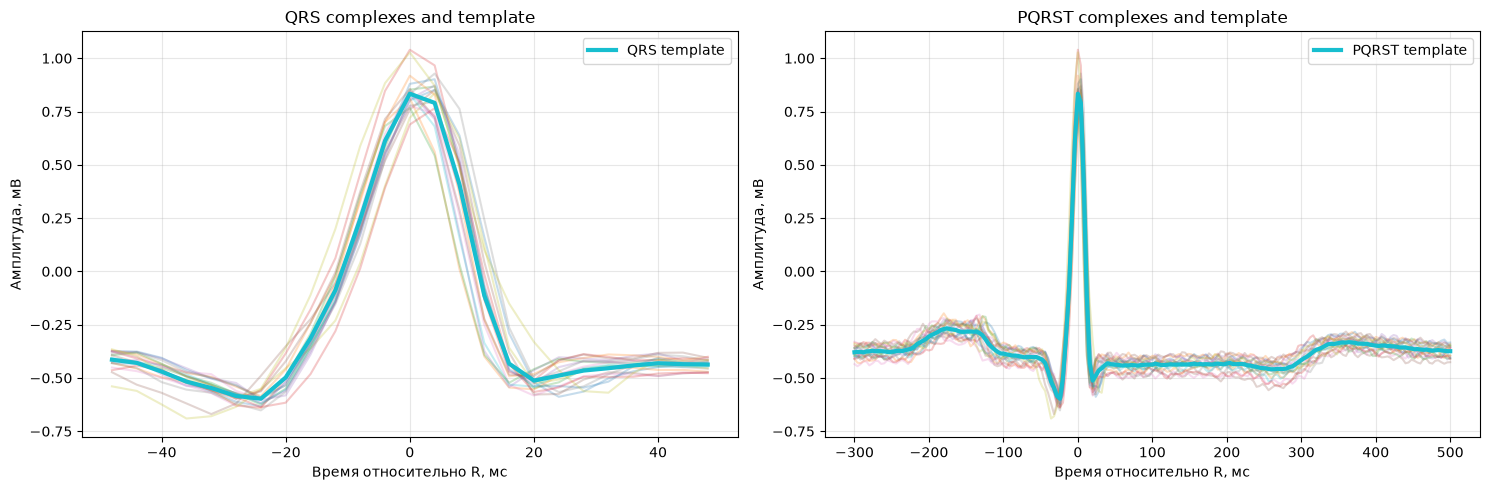

In [7]:
fig, axes = plt.subplots(
    1, 2,
    figsize=(15, 5)
)

# QRS
for complex_signal in qrs_complexes:
    axes[0].plot(
        qrs_time,
        complex_signal,
        alpha=0.25
    )

axes[0].plot(
    qrs_time,
    qrs_template,
    linewidth=3,
    label="QRS template"
)

axes[0].set_title("QRS complexes and template")
axes[0].set_xlabel("Время относительно R, мс")
axes[0].set_ylabel("Амплитуда, мВ")
axes[0].legend()
axes[0].grid(alpha=0.3)

# PQRST
for complex_signal in pqrst_complexes:
    axes[1].plot(
        pqrst_time,
        complex_signal,
        alpha=0.25
    )

axes[1].plot(
    pqrst_time,
    pqrst_template,
    linewidth=3,
    label="PQRST template"
)

axes[1].set_title("PQRST complexes and template")
axes[1].set_xlabel("Время относительно R, мс")
axes[1].set_ylabel("Амплитуда, мВ")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [8]:
from scipy.stats import pearsonr

# Выбираем первый QRS-комплекс
first_qrs = qrs_complexes[0]

# Сравниваем его с усреднённым шаблоном
result = pearsonr(first_qrs, qrs_template)

print(f"Корреляция первого QRS: {result.statistic:.6f}")

Корреляция первого QRS: 0.982504


In [9]:
# Корреляции QRS-комплексов
qrs_correlations = []

for complex_signal in qrs_complexes:

    r = pearsonr(
        complex_signal,
        qrs_template
    ).statistic

    qrs_correlations.append(r)


# Корреляции PQRST-комплексов
pqrst_correlations = []

for complex_signal in pqrst_complexes:

    r = pearsonr(
        complex_signal,
        pqrst_template
    ).statistic

    pqrst_correlations.append(r)


# Преобразуем списки в NumPy-массивы
qrs_correlations = np.asarray(qrs_correlations)
pqrst_correlations = np.asarray(pqrst_correlations)

In [10]:
r_qrs = np.mean(qrs_correlations)
r_pqrst = np.mean(pqrst_correlations)

print(f"Количество комплексов: {len(qrs_correlations)}")

print(f"Средняя корреляция QRS:   {r_qrs:.6f}")
print(f"Средняя корреляция PQRST: {r_pqrst:.6f}")

Количество комплексов: 19
Средняя корреляция QRS:   0.985596
Средняя корреляция PQRST: 0.982101


,beat_number,r_qrs,r_pqrst
0,1,0.982504,0.981691
1,2,0.969392,0.969122
2,3,0.997120,0.993616
3,4,0.995397,0.990216
4,5,0.980662,0.972828
5,6,0.981762,0.979973
6,7,0.995738,0.992722
7,8,0.971580,0.972286
8,9,0.967732,0.963768
9,10,0.987599,0.984125


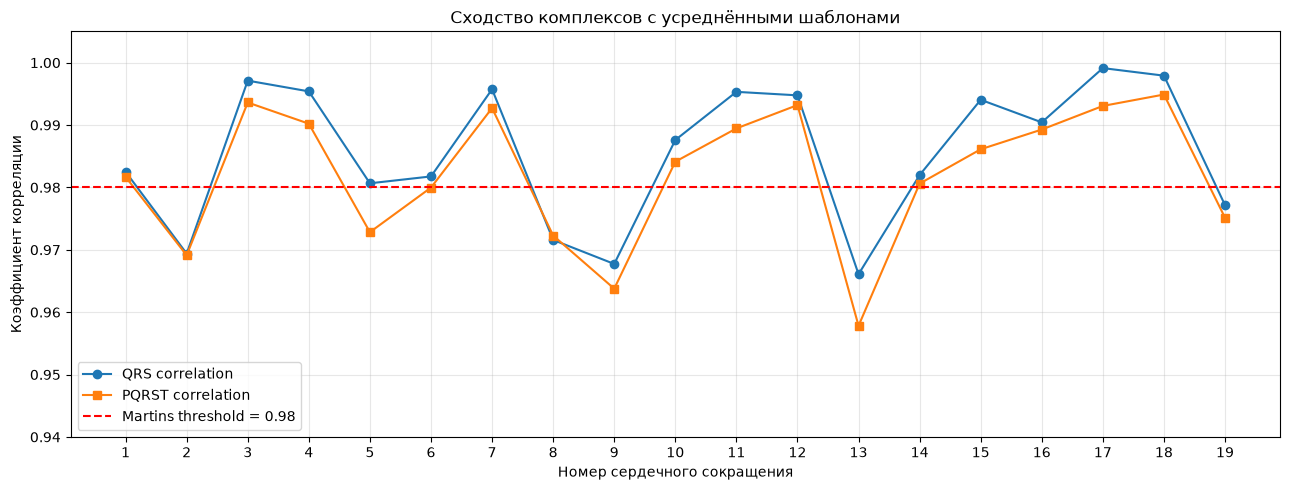

In [13]:
import pandas as pd

correlation_df = pd.DataFrame({
    "beat_number": np.arange(1, len(qrs_correlations) + 1),
    "r_qrs": qrs_correlations,
    "r_pqrst": pqrst_correlations
})

display(correlation_df)

fig, ax = plt.subplots(figsize=(13, 5))

ax.plot(
    correlation_df["beat_number"],
    correlation_df["r_qrs"],
    marker="o",
    label="QRS correlation"
)

ax.plot(
    correlation_df["beat_number"],
    correlation_df["r_pqrst"],
    marker="s",
    label="PQRST correlation"
)

ax.axhline(
    0.98,
    color="red",
    linestyle="--",
    label="Martins threshold = 0.98"
)

ax.set_xlabel("Номер сердечного сокращения")
ax.set_ylabel("Коэффициент корреляции")
ax.set_title("Сходство комплексов с усреднёнными шаблонами")

ax.set_ylim(0.94, 1.005)
ax.set_xticks(correlation_df["beat_number"])
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

Номер комплекса: 13
Корреляция: 0.966090


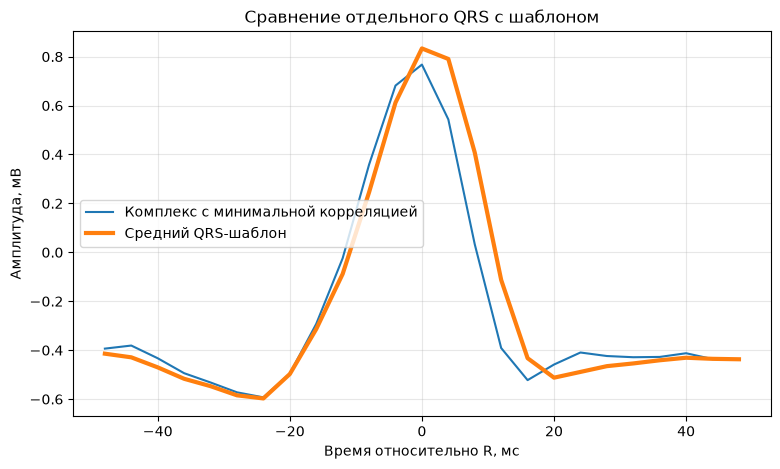

In [12]:
worst_idx = np.argmin(qrs_correlations)

print(f"Номер комплекса: {worst_idx + 1}")
print(f"Корреляция: {qrs_correlations[worst_idx]:.6f}")

plt.figure(figsize=(9, 5))

plt.plot(
    qrs_time,
    qrs_complexes[worst_idx],
    label="Комплекс с минимальной корреляцией"
)

plt.plot(
    qrs_time,
    qrs_template,
    linewidth=3,
    label="Средний QRS-шаблон"
)

plt.xlabel("Время относительно R, мс")
plt.ylabel("Амплитуда, мВ")
plt.title("Сравнение отдельного QRS с шаблоном")

plt.legend()
plt.grid(alpha=0.3)
plt.show()

# Проверка физиологической правдоподобности RR-интервалов

In [14]:
rr_ms = np.diff(segment_beats) / fs * 1000

print("Количество сокращений:", len(segment_beats))
print("Количество RR-интервалов:", len(rr_ms))
print("RR, мс:", np.round(rr_ms, 2))

Количество сокращений: 19
Количество RR-интервалов: 18
RR, мс: [828. 800. 836. 792. 788. 820. 844. 880. 824. 776. 804. 812. 796. 836.
 832. 824. 812. 788.]


In [15]:
def check_rr_plausibility(beat_samples, fs):
    # Рассчитываем RR в миллисекундах
    rr_ms = np.diff(beat_samples) / fs * 1000

    if len(rr_ms) == 0:
        raise ValueError("Недостаточно сокращений для расчёта RR")

    # Этап 1. Физиологический диапазон
    range_mask = (rr_ms >= 333) & (rr_ms <= 2000)

    rr_in_range = rr_ms[range_mask]

    # Маска всех интервалов, которые останутся после проверки
    valid_mask = np.zeros(len(rr_ms), dtype=bool)

    if len(rr_in_range) > 0:
        # Этап 2. Медиана
        median_rr = np.median(rr_in_range)

        # Допускаем отклонение не более 33%
        median_mask = (
            np.abs(rr_in_range - median_rr)
            <= 0.33 * median_rr
        )

        valid_mask[np.flatnonzero(range_mask)] = median_mask
    else:
        median_rr = np.nan

    rr_valid = rr_ms[valid_mask]
    outlier_count = len(rr_ms) - len(rr_valid)

    # Этап 3. Статистические характеристики
    if len(rr_valid) >= 2:
        mean_rr = np.mean(rr_valid)
        std_rr = np.std(rr_valid, ddof=0)
    else:
        mean_rr = np.nan
        std_rr = np.nan

    # Итоговые критерии
    plausible = (
        len(rr_valid) >= 2
        and 1 <= std_rr <= 200
        and outlier_count <= 2
    )

    return {
        "rr_ms": rr_ms,
        "valid_mask": valid_mask,
        "median_rr_ms": median_rr,
        "mean_rr_ms": mean_rr,
        "std_rr_ms": std_rr,
        "outlier_count": outlier_count,
        "plausible": bool(plausible)
    }

In [16]:
rr_result = check_rr_plausibility(
    beat_samples=segment_beats,
    fs=fs
)

print(f"Медиана RR: {rr_result['median_rr_ms']:.2f} мс")
print(f"Средний RR: {rr_result['mean_rr_ms']:.2f} мс")
print(f"STD RR: {rr_result['std_rr_ms']:.2f} мс")

print("Количество выбросов:", rr_result["outlier_count"])
print("RR plausible:", rr_result["plausible"])

Медиана RR: 816.00 мс
Средний RR: 816.22 мс
STD RR: 24.49 мс
Количество выбросов: 0
RR plausible: True


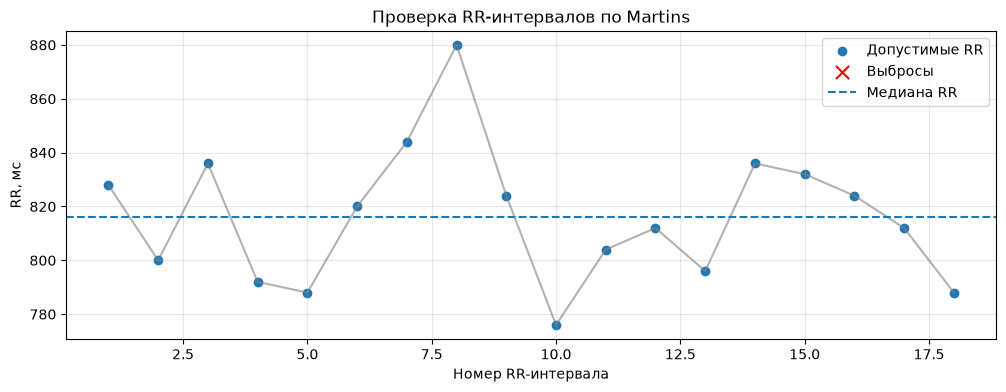

In [17]:
rr_values = rr_result["rr_ms"]
valid_mask = rr_result["valid_mask"]

beat_numbers = np.arange(1, len(rr_values) + 1)

plt.figure(figsize=(12, 4))

plt.plot(
    beat_numbers,
    rr_values,
    color="gray",
    alpha=0.6
)

plt.scatter(
    beat_numbers[valid_mask],
    rr_values[valid_mask],
    label="Допустимые RR"
)

plt.scatter(
    beat_numbers[~valid_mask],
    rr_values[~valid_mask],
    color="red",
    marker="x",
    s=90,
    label="Выбросы"
)

plt.axhline(
    rr_result["median_rr_ms"],
    linestyle="--",
    label="Медиана RR"
)

plt.xlabel("Номер RR-интервала")
plt.ylabel("RR, мс")
plt.title("Проверка RR-интервалов по Martins")

plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [18]:
def classify_martins(r_qrs, r_pqrst, rr_plausible):

    threshold = 0.98

    if not rr_plausible:
        return 4

    if r_qrs >= threshold and r_pqrst >= threshold:
        return 1

    if r_qrs >= threshold and r_pqrst < threshold:
        return 2

    if r_qrs < threshold and r_pqrst < threshold:
        return 3

    return None

In [19]:
quality_class = classify_martins(
    r_qrs=r_qrs,
    r_pqrst=r_pqrst,
    rr_plausible=rr_result["plausible"]
)

print(f"Средняя корреляция QRS: {r_qrs:.6f}")
print(f"Средняя корреляция PQRST: {r_pqrst:.6f}")
print(f"RR plausible: {rr_result['plausible']}")
print(f"Класс качества: {quality_class}")

Средняя корреляция QRS: 0.985596
Средняя корреляция PQRST: 0.982101
RR plausible: True
Класс качества: 1


In [20]:
def analyze_martins_segment(ecg, fs, beat_samples, start_sec):
    segment_samples = 15 * fs

    start = int(round(start_sec * fs))
    end = start + segment_samples

    if end > len(ecg):
        raise ValueError("Недостаточно данных для 15-секундного сегмента")

    # Сокращения, принадлежащие основному сегменту
    mask = (beat_samples >= start) & (beat_samples < end)
    beats = beat_samples[mask]

    # Проверяем, хватает ли данных для полного PQRST
    before = int(round(0.300 * fs))
    after = int(round(0.500 * fs))

    valid = (
        (beats - before >= 0)
        & (beats + after < len(ecg))
    )

    beats = beats[valid]

    # Недостаточно сокращений для анализа
    if len(beats) < 3:
        return {
            "start_s": start_sec,
            "n_beats": len(beats),
            "r_qrs": np.nan,
            "r_pqrst": np.nan,
            "rr_std_ms": np.nan,
            "rr_outliers": np.nan,
            "rr_plausible": None,
            "quality_class": None
        }

    # Выделение комплексов
    qrs, _ = extract_complexes(
        ecg, beats, fs, 50, 50
    )

    pqrst, _ = extract_complexes(
        ecg, beats, fs, 300, 500
    )

    # Усреднённые шаблоны
    qrs_template = np.mean(qrs, axis=0)
    pqrst_template = np.mean(pqrst, axis=0)

    # Корреляции отдельных комплексов
    qrs_r = [
        pearsonr(x, qrs_template).statistic
        for x in qrs
    ]

    pqrst_r = [
        pearsonr(x, pqrst_template).statistic
        for x in pqrst
    ]

    r_qrs = float(np.mean(qrs_r))
    r_pqrst = float(np.mean(pqrst_r))

    # RR plausibility
    rr_result = check_rr_plausibility(beats, fs)

    # Классификация
    if np.isfinite(r_qrs) and np.isfinite(r_pqrst):
        quality_class = classify_martins(
            r_qrs,
            r_pqrst,
            rr_result["plausible"]
        )
    else:
        quality_class = None

    return {
        "start_s": start_sec,
        "n_beats": len(beats),
        "r_qrs": r_qrs,
        "r_pqrst": r_pqrst,
        "rr_std_ms": rr_result["std_rr_ms"],
        "rr_outliers": rr_result["outlier_count"],
        "rr_plausible": rr_result["plausible"],
        "quality_class": quality_class
    }

In [21]:
result_30 = analyze_martins_segment(
    ecg=ecg,
    fs=fs,
    beat_samples=reference_beats,
    start_sec=30
)

for key, value in result_30.items():
    print(f"{key}: {value}")

start_s: 30
n_beats: 19
r_qrs: 0.9855961122928212
r_pqrst: 0.9821013781000917
rr_std_ms: 24.493889386619486
rr_outliers: 0
rr_plausible: True
quality_class: 1


In [22]:
import pandas as pd

segment_duration = 15
record_duration = len(ecg) / fs

results = []

for start_sec in range(
    0,
    int(record_duration) - segment_duration + 1,
    segment_duration
):
    result = analyze_martins_segment(
        ecg=ecg,
        fs=fs,
        beat_samples=reference_beats,
        start_sec=start_sec
    )

    results.append(result)

sqa_df = pd.DataFrame(results)

display(sqa_df.head(10))

,start_s,n_beats,r_qrs,r_pqrst,rr_std_ms,rr_outliers,rr_plausible,quality_class
0,0,18,0.986608,0.982285,63.149189,0,True,1
1,15,18,0.984192,0.981577,27.546500,0,True,1
2,30,19,0.985596,0.982101,24.493889,0,True,1
3,45,18,0.981133,0.977480,24.275238,0,True,2
4,60,19,0.979995,0.977265,23.257018,0,True,3
5,75,18,0.983933,0.981796,21.376830,0,True,1
6,90,19,0.985737,0.982391,25.298221,0,True,1
7,105,18,0.982676,0.977801,28.622831,0,True,2
8,120,19,0.982594,0.977215,22.637236,0,True,2
9,135,19,0.984749,0.979397,22.310934,0,True,2


In [23]:
print("Всего сегментов:", len(sqa_df))

print("\nРаспределение классов:")
print(
    sqa_df["quality_class"]
    .value_counts(dropna=False)
    .sort_index()
)

Всего сегментов: 120

Распределение классов:
quality_class
1    27
2    52
3    41
Name: count, dtype: int64


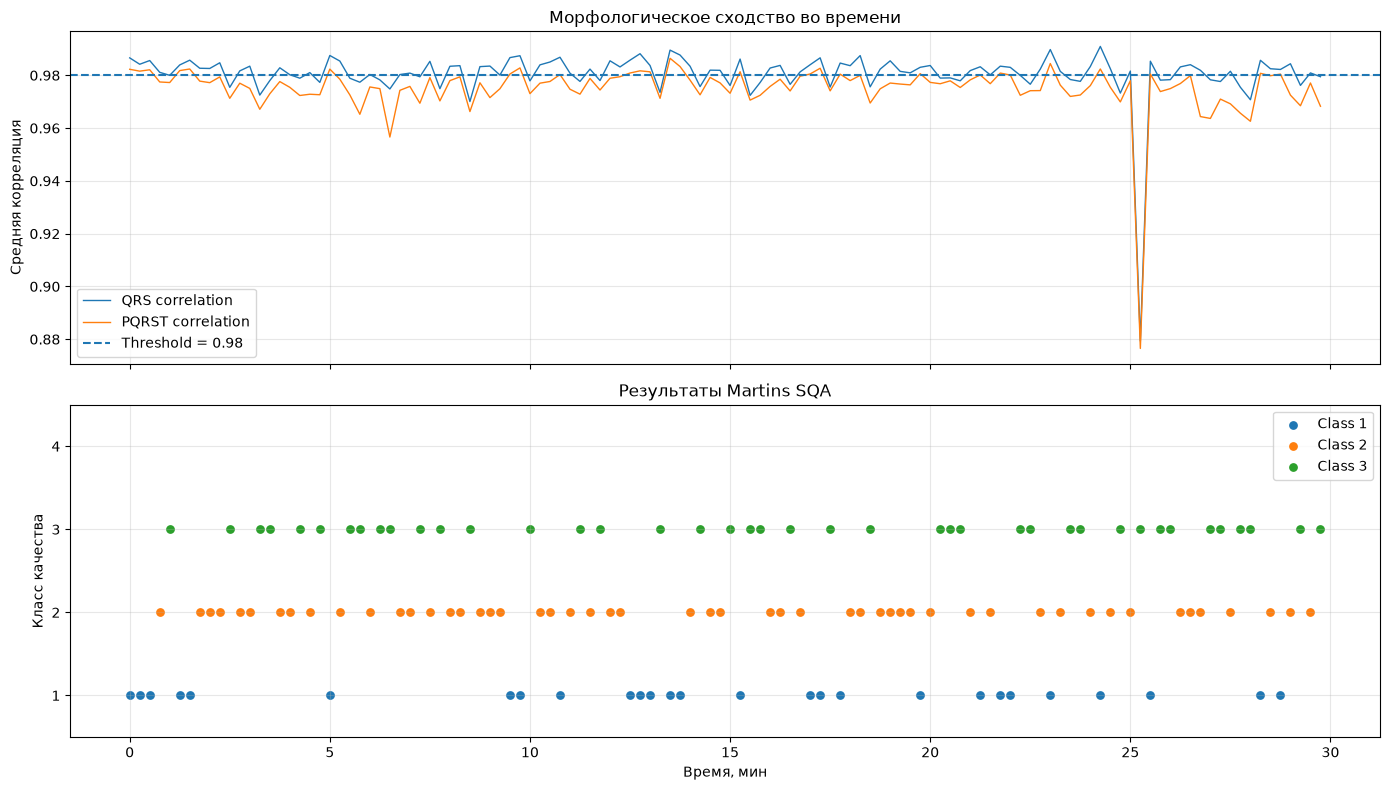

In [24]:
# Переводим время из секунд в минуты
time_min = sqa_df["start_s"] / 60

fig, axes = plt.subplots(
    2, 1,
    figsize=(14, 8),
    sharex=True
)

# График 1. Корреляции
axes[0].plot(
    time_min,
    sqa_df["r_qrs"],
    label="QRS correlation",
    linewidth=1
)

axes[0].plot(
    time_min,
    sqa_df["r_pqrst"],
    label="PQRST correlation",
    linewidth=1
)

axes[0].axhline(
    0.98,
    linestyle="--",
    label="Threshold = 0.98"
)

axes[0].set_ylabel("Средняя корреляция")
axes[0].set_title("Морфологическое сходство во времени")
axes[0].legend()
axes[0].grid(alpha=0.3)

# График 2. Классы качества
for quality_class, group in sqa_df.groupby("quality_class"):
    axes[1].scatter(
        group["start_s"] / 60,
        group["quality_class"],
        label=f"Class {quality_class}",
        s=28
    )

axes[1].set_yticks([1, 2, 3, 4])
axes[1].set_ylim(0.5, 4.5)
axes[1].set_ylabel("Класс качества")
axes[1].set_xlabel("Время, мин")
axes[1].set_title("Результаты Martins SQA")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()